# Smart MCQ Solver — Combined Notebook

This notebook contains **three models** for the Smart MCQ Solver Challenge:

1. **Model 1 (from scratch):** BiLSTM + Attention (Keras/TensorFlow, trained from random init, GloVe embeddings only)
2. **Model 2 (pretrained):** BERT (`bert-base-uncased`) fine-tuned for Multiple Choice
3. **Model 3 (model of choice):** Wikipedia-RAG + Sentence-Embedding similarity (no training, retrieval-based)


- **Model 1** trains with **5-fold Stratified CV** on the full training set
  (one W&B run per fold, plus a summary run with the out-of-fold metrics).
  **Models 2 & 3** use a single shared 80/20 train/valid split for speed.


## 0. Common Setup (always run this first)

In [1]:
!pip install -q \
langchain-community \
langchain-huggingface \
faiss-cpu \
sentence-transformers

!pip install -U bitsandbytes>=0.46.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 86.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.6/561.6 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 82.7 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy

In [2]:
# ==========================================
# COMMON SETUP 
# ==========================================
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

import wandb
from kaggle_secrets import UserSecretsClient

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------------
# Paths (Kaggle competition input)
# ------------------------------------------------------------------
TRAIN_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
TEST_PATH  = "/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv"

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)

print("Train shape:", train.shape)
print("Test shape :", test.shape)

# ------------------------------------------------------------------
# Label encoding (shared across all models)
# ------------------------------------------------------------------
label2id = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
id2label = {v: k for k, v in label2id.items()}
train["label"] = train["answer"].map(label2id)

# ------------------------------------------------------------------
# MAP@3 metric (competition metric)
# ------------------------------------------------------------------
def mapk(actual, predicted, k=3):
    """actual: list of true labels. predicted: list of ranked label lists."""
    score = 0.0
    for a, p in zip(actual, predicted):
        p = list(p[:k])
        if a in p:
            score += 1.0 / (p.index(a) + 1)
    return score / len(actual)

# ------------------------------------------------------------------
# One shared train/validation split so all 3 models are compared fairly
# ------------------------------------------------------------------
train_df, valid_df = train_test_split(
    train,
    test_size=0.2,
    stratify=train["label"],
    random_state=SEED
)
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)

print("Train split:", train_df.shape, "| Valid split:", valid_df.shape)

# ------------------------------------------------------------------
# Weights & Biases login (used by all 3 models)
# ------------------------------------------------------------------
user_secrets = UserSecretsClient()
WB_KEY = user_secrets.get_secret("wandb-key")
wandb.login(key=WB_KEY)

WANDB_PROJECT = "21f3002488-dl-genai-project"

print("Common setup complete.")


Train shape: (2000, 8)
Test shape : (500, 7)
Train split: (1600, 9) | Valid split: (400, 9)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Common setup complete.


In [3]:
print("=" * 50)
print("Train Shape :", train.shape)
print("Test Shape  :", test.shape)
print("=" * 50)

Train Shape : (2000, 9)
Test Shape  : (500, 7)


In [4]:
# ==========================================
# View Dataset
# ==========================================

print("Train Dataset")
display(train.head())

print("\nTest Dataset")
display(test.head())

Train Dataset


,id,prompt,A,B,C,D,E,answer,label
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,1
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A,0
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C,2
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,1
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A,0



Test Dataset


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [5]:
# ==========================================
# Dataset Information
# ==========================================

print("TRAIN INFO")
print("-" * 40)
train.info()

print("\nTEST INFO")
print("-" * 40)
test.info()

TRAIN INFO
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
 8   label   2000 non-null   int64 
dtypes: int64(2), object(7)
memory usage: 140.8+ KB

TEST INFO
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      500 non-null    int64 
 1   prompt  500 non-null    object
 2   A       500 non-null    object
 3   B       500 non-null    object
 4   C       500 non-n

In [6]:
# ==========================================
# Missing Values
# ==========================================

print("Train Missing Values")
display(train.isnull().sum())

print("\nTest Missing Values")
display(test.isnull().sum())

Train Missing Values


id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
label     0
dtype: int64


Test Missing Values


id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64

In [7]:
# ==========================================
# Duplicate Prompts
# ==========================================

duplicates = train["prompt"].duplicated().sum()

print(f"Duplicate Questions : {duplicates}")

Duplicate Questions : 242


In [8]:
# All rows whose prompt appears more than once
duplicate_rows = train_df[train_df.duplicated(subset=['prompt'], keep=False)]

print("Number of rows involved in duplicates:", len(duplicate_rows))
display(duplicate_rows.sort_values('prompt'))

Number of rows involved in duplicates: 316


,id,prompt,A,B,C,D,E,answer,label
411,457,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E,4
1510,440,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E,4
460,606,Choose the correct answer: What are permutatio...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,Permutation-inversion groups are groups of sym...,E,4
1370,945,Choose the correct answer: What are the four q...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",B,1
7,1622,Choose the correct answer: What are the four q...,"Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...","Holocrystalline, hypohyaline, hypercrystalline...","Holocrystalline, hypocrystalline, hypercrystal...","Holocrystalline, hypocrystalline, hypohyaline,...",B,1
...,...,...,...,...,...,...,...,...,...
351,1046,Which of the following is correct? Which of th...,MOND is a concept that reduces the observed mi...,MOND is a principle that raises the discrepanc...,MOND is a framework that explains the missing ...,MOND is a framework that reduces the discrepan...,MOND is a framework that eliminates the observ...,D,3
1030,709,Which of the following is correct? Who propose...,Ilya Prigogine in 1979,Henri Atlan in 1972,Democritus and Lucretius in ancient times,None of the above.,René Descartes in 1637,B,1
902,1650,Which of the following is correct? Who propose...,Ilya Prigogine in 1979,Henri Atlan in 1972,Democritus and Lucretius in ancient times,None of the above.,René Descartes in 1637,B,1
316,1624,Which of the following is correct? Who was Gio...,A German philosopher who supported the Kepleri...,An English philosopher who supported the Ptole...,A French philosopher who supported the Aristot...,An Italian philosopher who supported the Coper...,A Spanish philosopher who supported the Galile...,D,3


answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


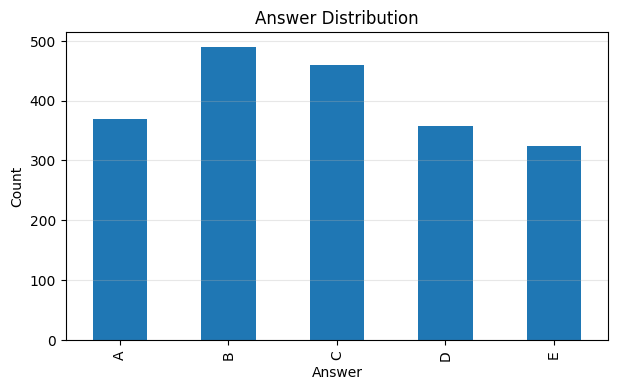

In [9]:
# ==========================================
# Target Distribution
# ==========================================

print(train["answer"].value_counts())

plt.figure(figsize=(7,4))

train["answer"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Answer Distribution")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)

plt.show()

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_length, dtype: float64


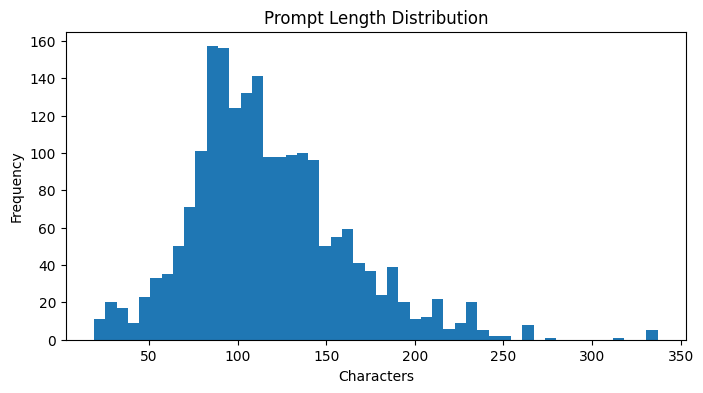

In [10]:
# ==========================================
# Prompt Length
# ==========================================

train["prompt_length"] = train["prompt"].astype(str).apply(len)

print(train["prompt_length"].describe())

plt.figure(figsize=(8,4))

plt.hist(train["prompt_length"], bins=50)

plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

count    2000.000000
mean      942.398000
std       521.720751
min        84.000000
25%       566.000000
50%       870.500000
75%      1258.000000
max      2603.000000
Name: combined_length, dtype: float64


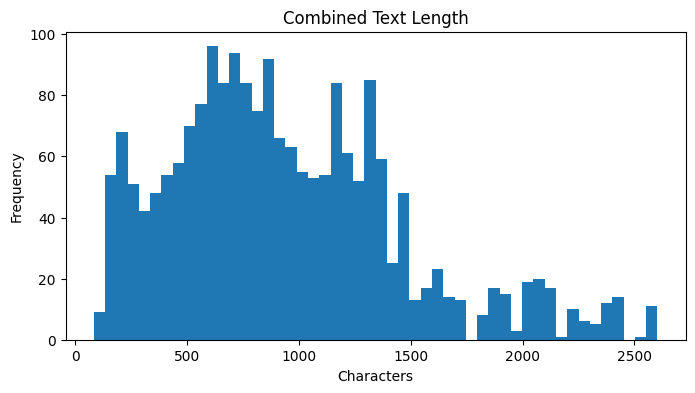

In [11]:
# ==========================================
# Combined Text Length
# ==========================================

train["combined_length"] = (
    train["prompt"].astype(str) +
    train["A"].astype(str) +
    train["B"].astype(str) +
    train["C"].astype(str) +
    train["D"].astype(str) +
    train["E"].astype(str)
).apply(len)

print(train["combined_length"].describe())

plt.figure(figsize=(8,4))

plt.hist(train["combined_length"], bins=50)

plt.title("Combined Text Length")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

In [12]:
# ==========================================
# Label Balance
# ==========================================

label_percent = (
    train["answer"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(label_percent)

answer
A    18.45
B    24.50
C    22.95
D    17.90
E    16.20
Name: proportion, dtype: float64

## 1. Choose which model(s) to run

In [13]:
# ==========================================
# RUN FLAGS
# Set the model you want to run to True and the others to False.
# ==========================================
RUN_MODEL_1_SCRATCH    = False    # Model 1: BiLSTM + Attention (from scratch)
RUN_MODEL_2_PRETRAINED = True   # Model 2: BERT (pretrained, fine-tuned)
RUN_MODEL_3_CUSTOM     = False   # Model 3: Wikipedia RAG + embedding similarity

print("Model 1 (scratch)   :", RUN_MODEL_1_SCRATCH)
print("Model 2 (pretrained):", RUN_MODEL_2_PRETRAINED)
print("Model 3 (custom)    :", RUN_MODEL_3_CUSTOM)


Model 1 (scratch)   : False
Model 2 (pretrained): True
Model 3 (custom)    : False


## 2. Model 1 — BiLSTM + Attention (built from scratch)

Trained from random initialization (only the GloVe word embeddings are
pretrained; the LSTM/Attention/Dense layers are trained from scratch).
Runs only if `RUN_MODEL_1_SCRATCH = True`.

In [14]:
if RUN_MODEL_1_SCRATCH:

    import tensorflow as tf
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Model
    from tensorflow.keras.layers import (
        Input, Embedding, LSTM, Bidirectional, Dense, Dropout,
        Layer, SpatialDropout1D
    )
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
    from tensorflow.keras.optimizers import Adam
    import tensorflow.keras.backend as K
    from sklearn.model_selection import StratifiedKFold
    from wandb.integration.keras import WandbMetricsLogger

    tf.random.set_seed(SEED)

    # ------------------------------
    # Config
    # ------------------------------
    MAX_VOCAB_SIZE = 50000
    MAX_LEN        = 384
    EMBEDDING_DIM  = 100
    BATCH_SIZE     = 32
    EPOCHS         = 20
    N_SPLITS       = 5

    # Model 1 uses the FULL training set with 5-fold CV (not the shared
    # single split used by Models 2 & 3), matching the original workflow.
    m1_train = train.copy()
    m1_test  = test.copy()

    # ------------------------------
    # Text cleaning + combining
    # ------------------------------
    import re

    def clean_text(text):
        if pd.isna(text):
            return ""
        text = str(text).lower()
        text = re.sub(r"<.*?>", " ", text)
        text = re.sub(r"http\S+|www\S+", " ", text)
        text = re.sub(r"\s+", " ", text)
        return text.strip()

    def combine_text(row):
        return (
            "Question: " + row["prompt"] +
            " [SEP] Option A: " + row["A"] +
            " [SEP] Option B: " + row["B"] +
            " [SEP] Option C: " + row["C"] +
            " [SEP] Option D: " + row["D"] +
            " [SEP] Option E: " + row["E"]
        )

    text_columns = ["prompt", "A", "B", "C", "D", "E"]

    for col in text_columns:
        m1_train[col] = m1_train[col].apply(clean_text)
        m1_test[col]  = m1_test[col].apply(clean_text)

    m1_train["combined_text"] = m1_train.apply(combine_text, axis=1)
    m1_test["combined_text"]  = m1_test.apply(combine_text, axis=1)

    # ------------------------------
    # Tokenizer + padding
    # ------------------------------
    tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
    tokenizer.fit_on_texts(m1_train["combined_text"])

    X = pad_sequences(
        tokenizer.texts_to_sequences(m1_train["combined_text"]),
        maxlen=MAX_LEN, padding="post", truncating="post"
    )
    X_test = pad_sequences(
        tokenizer.texts_to_sequences(m1_test["combined_text"]),
        maxlen=MAX_LEN, padding="post", truncating="post"
    )

    y = m1_train["label"].values

    word_index = tokenizer.word_index
    vocab_size = min(MAX_VOCAB_SIZE, len(word_index) + 1)

    # ------------------------------
    # GloVe embeddings
    # ------------------------------
    GLOVE_PATH = "/kaggle/input/datasets/danielwillgeorge/glove6b100dtxt/glove.6B.100d.txt"

    embeddings_index = {}
    with open(GLOVE_PATH, encoding="utf8") as f:
        for line in f:
            values = line.split()
            embeddings_index[values[0]] = np.asarray(values[1:], dtype="float32")

    embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM))
    for word, idx in word_index.items():
        if idx >= vocab_size:
            continue
        vector = embeddings_index.get(word)
        if vector is not None:
            embedding_matrix[idx] = vector

    print("GloVe coverage ready. Vocab size:", vocab_size)

    # ------------------------------
    # Custom attention layer
    # ------------------------------
    class AttentionLayer(Layer):
        def __init__(self, **kwargs):
            super().__init__(**kwargs)

        def build(self, input_shape):
            self.W = self.add_weight(
                name="attention_weight", shape=(input_shape[-1], 1),
                initializer="glorot_uniform", trainable=True
            )
            self.b = self.add_weight(
                name="attention_bias", shape=(input_shape[1], 1),
                initializer="zeros", trainable=True
            )
            super().build(input_shape)

        def call(self, inputs):
            e = K.tanh(K.dot(inputs, self.W) + self.b)
            a = K.softmax(e, axis=1)
            context = K.sum(inputs * a, axis=1)
            return context

    # ------------------------------
    # Build model
    # ------------------------------
    def build_model():
        inputs = Input(shape=(MAX_LEN,), name="Input")

        x = Embedding(
            input_dim=vocab_size, output_dim=EMBEDDING_DIM,
            weights=[embedding_matrix], input_length=MAX_LEN,
            trainable=False, name="Embedding"
        )(inputs)
        x = SpatialDropout1D(0.3)(x)

        x = Bidirectional(LSTM(128, return_sequences=True, dropout=0.3,
                                recurrent_dropout=0.3))(x)
        x = Bidirectional(LSTM(64, return_sequences=True, dropout=0.3,
                                recurrent_dropout=0.3))(x)

        x = AttentionLayer()(x)

        x = Dense(256, activation="relu")(x)
        x = Dropout(0.4)(x)
        x = Dense(128, activation="relu")(x)
        x = Dropout(0.3)(x)

        outputs = Dense(5, activation="softmax", name="Output")(x)
        return Model(inputs, outputs)

    # ------------------------------
    # 5-Fold Stratified Cross Validation
    # ------------------------------
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

    oof_pred  = np.zeros((len(m1_train), 5))
    test_pred = np.zeros((len(m1_test), 5))

    fold_accuracy = []
    fold_f1 = []

    for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y), 1):

        print("=" * 60)
        print(f"Model 1 - Fold {fold}/{N_SPLITS}")
        print("=" * 60)

        # Fresh W&B run per fold
        wandb.init(
            project=WANDB_PROJECT,
            name=f"Model1_BiLSTM_Attention_Fold_{fold}",
            reinit=True,
            config={
                "Model": "BiLSTM + Attention (from scratch)",
                "Embeddings": "GloVe 100d",
                "Batch Size": BATCH_SIZE,
                "Epochs": EPOCHS,
                "Max Length": MAX_LEN,
                "Optimizer": "Adam",
                "Learning Rate": 1e-3,
                "Fold": fold
            }
        )

        # Fresh callbacks each fold
        early_stop = EarlyStopping(monitor="val_loss", patience=3,
                                    restore_best_weights=True, verbose=1)
        reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                       patience=2, min_lr=1e-6, verbose=1)
        checkpoint = ModelCheckpoint(
            f"best_model_fold_{fold}.keras",
            monitor="val_loss", save_best_only=True, verbose=1
        )

        callbacks = [early_stop, reduce_lr, checkpoint, WandbMetricsLogger()]

        X_train, X_valid = X[train_idx], X[valid_idx]
        y_train, y_valid = y[train_idx], y[valid_idx]

        model = build_model()
        model.compile(
            optimizer=Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        model.fit(
            X_train, y_train,
            validation_data=(X_valid, y_valid),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=callbacks,
            verbose=1
        )

        # Predictions
        valid_prob = model.predict(X_valid, verbose=0)
        fold_test  = model.predict(X_test, verbose=0)

        oof_pred[valid_idx] = valid_prob
        test_pred += fold_test / N_SPLITS

        pred_label = np.argmax(valid_prob, axis=1)

        acc = accuracy_score(y_valid, pred_label)
        macro_f1 = f1_score(y_valid, pred_label, average="macro")

        fold_accuracy.append(acc)
        fold_f1.append(macro_f1)

        print(f"Fold {fold} Accuracy : {acc:.4f}")
        print(f"Fold {fold} Macro F1 : {macro_f1:.4f}")

        wandb.log({
            "Validation Accuracy": acc,
            "Validation Macro F1": macro_f1
        })
        wandb.finish()

    # ------------------------------
    # Overall (OOF) evaluation across all 5 folds
    # ------------------------------
    overall_pred = np.argmax(oof_pred, axis=1)
    overall_acc  = accuracy_score(y, overall_pred)
    overall_f1   = f1_score(y, overall_pred, average="macro")

    oof_top3 = np.argsort(oof_pred, axis=1)[:, -3:][:, ::-1]
    oof_labels = [[id2label[i] for i in row] for row in oof_top3]
    oof_map3 = mapk(m1_train["answer"].tolist(), oof_labels, k=3)

    print("=" * 60)
    print("Model 1 - 5-Fold CV Finished")
    print("=" * 60)
    print(f"Mean Fold Accuracy : {np.mean(fold_accuracy):.4f}")
    print(f"Mean Fold Macro F1 : {np.mean(fold_f1):.4f}")
    print(f"OOF Accuracy       : {overall_acc:.4f}")
    print(f"OOF Macro F1       : {overall_f1:.4f}")
    print(f"OOF MAP@3          : {oof_map3:.4f}")

    # Single summary run, named to match Model 2 / Model 3 for easy comparison
    wandb.init(
        project=WANDB_PROJECT,
        name="Model1_BiLSTM_Attention_Scratch",
        reinit=True,
        config={
            "Model": "BiLSTM + Attention (from scratch)",
            "Embeddings": "GloVe 100d",
            "Folds": N_SPLITS,
            "Epochs": EPOCHS,
            "Batch Size": BATCH_SIZE
        }
    )
    wandb.log({
        "Validation Accuracy": overall_acc,
        "Validation Macro F1": overall_f1,
        "Validation MAP@3": oof_map3
    })
    wandb.finish()

    # ------------------------------
    # Predict on test (averaged over folds) + save submission
    # ------------------------------
    top3_idx_test = np.argsort(test_pred, axis=1)[:, -3:][:, ::-1]
    predictions = [" ".join(id2label[i] for i in row) for row in top3_idx_test]

    submission_1 = pd.DataFrame({"ID": m1_test["id"], "Prediction": predictions})
    submission_1.to_csv("submission.csv", index=False)
    print("Saved submission.csv")
    display(submission.head())

else:
    print("Skipping Model 1 (RUN_MODEL_1_SCRATCH = False)")


Skipping Model 1 (RUN_MODEL_1_SCRATCH = False)


## 3. Model 2 — BERT (pretrained, fine-tuned)

Uses `bert-base-uncased` from Hugging Face with `AutoModelForMultipleChoice`,
fine-tuned on the MCQ data. Runs only if `RUN_MODEL_2_PRETRAINED = True`.

In [15]:
if RUN_MODEL_2_PRETRAINED:

    import torch
    from torch.utils.data import Dataset, DataLoader
    from torch.optim import AdamW
    from transformers import (
        AutoTokenizer, AutoModelForMultipleChoice,
        get_linear_schedule_with_warmup
    )
    from tqdm.auto import tqdm

    MODEL_NAME = "bert-base-uncased"
    MAX_LEN    = 256
    BATCH_SIZE = 8
    EPOCHS     = 3
    LR         = 2e-5

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", DEVICE)

    bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    class MCQDataset(Dataset):
        def __init__(self, dataframe, tokenizer, max_len=256, is_test=False):
            self.df = dataframe.reset_index(drop=True)
            self.tokenizer = tokenizer
            self.max_len = max_len
            self.is_test = is_test

        def __len__(self):
            return len(self.df)

        def __getitem__(self, idx):
            row = self.df.iloc[idx]
            prompt = row["prompt"]
            choices = [row["A"], row["B"], row["C"], row["D"], row["E"]]

            encoding = self.tokenizer(
                [prompt] * 5, choices,
                truncation=True, padding="max_length",
                max_length=self.max_len, return_tensors="pt"
            )

            item = {
                "input_ids": encoding["input_ids"],
                "attention_mask": encoding["attention_mask"],
            }
            if "token_type_ids" in encoding:
                item["token_type_ids"] = encoding["token_type_ids"]
            if not self.is_test:
                item["labels"] = torch.tensor(row["label"], dtype=torch.long)
            return item

    train_dataset = MCQDataset(train_df, bert_tokenizer, MAX_LEN)
    valid_dataset = MCQDataset(valid_df, bert_tokenizer, MAX_LEN)
    test_dataset  = MCQDataset(test, bert_tokenizer, MAX_LEN, is_test=True)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(DEVICE)
    optimizer = AdamW(model.parameters(), lr=LR)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=0, num_training_steps=total_steps
    )

    run = wandb.init(
        project=WANDB_PROJECT,
        name="Model2_BERT_Pretrained",
        reinit=True,
        config={
            "Model": MODEL_NAME,
            "Batch Size": BATCH_SIZE,
            "Epochs": EPOCHS,
            "Max Length": MAX_LEN,
            "Learning Rate": LR
        }
    )

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch+1}/{EPOCHS}")

        model.train()
        train_loss = 0
        for batch in tqdm(train_loader):
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            kwargs = dict(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            if "token_type_ids" in batch:
                kwargs["token_type_ids"] = batch["token_type_ids"].to(DEVICE)

            outputs = model(**kwargs)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            scheduler.step()
            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)
        print(f"Train Loss: {avg_train_loss:.4f}")
        wandb.log({"epoch": epoch + 1, "train_loss": avg_train_loss})

    # ------------------------------
    # Validation
    # ------------------------------
    model.eval()
    val_logits, targets = [], []
    with torch.no_grad():
        for batch in tqdm(valid_loader):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            kwargs = dict(input_ids=input_ids, attention_mask=attention_mask)
            if "token_type_ids" in batch:
                kwargs["token_type_ids"] = batch["token_type_ids"].to(DEVICE)

            outputs = model(**kwargs)
            val_logits.append(outputs.logits.cpu())
            targets.extend(labels.cpu().numpy())

    val_logits = torch.cat(val_logits).numpy()
    pred_label = np.argmax(val_logits, axis=1)

    acc = accuracy_score(targets, pred_label)
    macro_f1 = f1_score(targets, pred_label, average="macro")

    top3_idx = np.argsort(-val_logits, axis=1)[:, :3]
    val_map3 = mapk(targets, top3_idx.tolist(), k=3)

    print(f"Model 2 (BERT) -> Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | MAP@3: {val_map3:.4f}")

    wandb.log({
        "Validation Accuracy": acc,
        "Validation Macro F1": macro_f1,
        "Validation MAP@3": val_map3
    })
    wandb.finish()

    # ------------------------------
    # Predict on test + save submission
    # ------------------------------
    model.eval()
    test_logits = []
    with torch.no_grad():
        for batch in tqdm(test_loader):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            kwargs = dict(input_ids=input_ids, attention_mask=attention_mask)
            if "token_type_ids" in batch:
                kwargs["token_type_ids"] = batch["token_type_ids"].to(DEVICE)

            outputs = model(**kwargs)
            test_logits.append(outputs.logits.cpu())

    test_logits = torch.cat(test_logits).numpy()
    top3_idx_test = np.argsort(-test_logits, axis=1)[:, :3]
    predictions = [" ".join(id2label[i] for i in row) for row in top3_idx_test]

    submission_2 = pd.DataFrame({"ID": test["id"], "Prediction": predictions})
    submission_2.to_csv("submission_model2.csv", index=False)
    print("Saved submission_model2.csv")
    display(submission_2.head())

else:
    print("Skipping Model 2 (RUN_MODEL_2_PRETRAINED = False)")


Device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (11 outputs left out)

Validation Accuracy,▁
Validation MAP@3,▁
Validation Macro F1,▁
epoch,▁▅█
train_loss,█▂▁
Validation Accuracy,0.955
Validation MAP@3,0.96917
Validation Macro F1,0.95499
epoch,3
train_loss,0.33788


  0%|          | 0/63 [00:00<?, ?it/s]

Saved submission_model2.csv


,ID,Prediction
0,1,A C D
1,2,B A D
2,3,B E C
3,4,E C A
4,5,C A B


## 4. Model 3 — Wikipedia RAG + Embedding Similarity (model of choice)

No fine-tuning: retrieves relevant Wikipedia context for each question,
embeds the prompt+option text with a sentence-transformer, and scores each
option by similarity to the retrieved context (FAISS). Runs only if
`RUN_MODEL_3_CUSTOM = True`.

In [16]:
BUILD_KNOWLEDGE_BASE = False   # <-- flipped to False after first successful run


# CONFIG / FLAGS
# ------------------------------------------------------------------
# KB_DIR: where the knowledge base files live.
#   - First run: this is your local Kaggle working dir ("/kaggle/working/mcq_kb")
#   - After you upload it as a Kaggle Dataset, change KB_DIR to point at
#     "/kaggle/input/<your-dataset-name>/mcq_kb" instead.
# ------------------------------------------------------------------
 
KB_DIR = "/kaggle/input/datasets/dhruvh4rm4/knowledge-database/mcq_kb"   # change to /kaggle/input/<dataset-name>/mcq_kb once uploaded
CORPUS_PKL_PATH = f"{KB_DIR}/wiki_corpus.pkl"
FAISS_INDEX_DIR = f"{KB_DIR}"

 
EMBED_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_SIZE    = 500
CHUNK_OVERLAP = 150
RETRIEVAL_K   = 4   # chunks pulled per question
 
os.makedirs(KB_DIR, exist_ok=True)


In [17]:
# %% CELL 2 -- BUILD KNOWLEDGE BASE (run once, then set BUILD_KNOWLEDGE_BASE=False)
# ------------------------------------------------------------------

if RUN_MODEL_3_CUSTOM and BUILD_KNOWLEDGE_BASE:
 
    get_ipython().system('pip install -q wikipedia langchain langchain-community langchain-huggingface langchain-text-splitters faiss-cpu sentence-transformers')
 
    import pickle, time
    import wikipedia
    from langchain_text_splitters import RecursiveCharacterTextSplitter
    from langchain_core.documents import Document
    from langchain_huggingface import HuggingFaceEmbeddings
    from langchain_community.vectorstores import FAISS
 
    wikipedia.set_lang("en")
    wikipedia.set_user_agent("SmartMCQSolver/1.0 (student@example.com)")
 
    # ---- 2a. Find candidate Wikipedia titles for every prompt ----
    def get_candidate_titles(prompt, k=3):
        try:
            return wikipedia.search(prompt, results=k)
        except Exception:
            return []
 
    all_prompts = pd.concat([train["prompt"], test["prompt"]]).tolist()
 
    all_titles = set()
    for p in all_prompts:
        all_titles.update(get_candidate_titles(p, k=3))
 
    print("Unique Wikipedia titles found:", len(all_titles))
 
    # ---- 2b. Pull page content for each title ----
    corpus = {}
    for title in all_titles:
        try:
            page = wikipedia.page(title, auto_suggest=False)
            corpus[title] = page.content
        except Exception:
            continue
        time.sleep(0.1)
 
    with open(CORPUS_PKL_PATH, "wb") as f:
        pickle.dump(corpus, f)
    print(f"Saved raw corpus -> {CORPUS_PKL_PATH}")
 
    # ---- 2c. Chunk + embed + build FAISS index ----
    docs = [Document(page_content=text, metadata={"title": title})
            for title, text in corpus.items()]
 
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE,
        chunk_overlap=CHUNK_OVERLAP
    )
    chunks = splitter.split_documents(docs)
    print(f"Created {len(chunks)} chunks from {len(docs)} pages")
 
    embeddings = HuggingFaceEmbeddings(model_name=EMBED_MODEL_NAME)
    vector_store = FAISS.from_documents(chunks, embeddings)
    vector_store.save_local(FAISS_INDEX_DIR)
    print(f"Saved FAISS index -> {FAISS_INDEX_DIR}")
 
else:
    print("Skipping knowledge-base build (BUILD_KNOWLEDGE_BASE = False). "
          "Will load a saved index in Cell 3 instead.")
 
 


Skipping knowledge-base build (BUILD_KNOWLEDGE_BASE = False). Will load a saved index in Cell 3 instead.


In [18]:
# LOAD KNOWLEDGE BASE 
# ------------------------------------------------------------------
if RUN_MODEL_3_CUSTOM:
    from langchain_huggingface import HuggingFaceEmbeddings
    from langchain_huggingface import HuggingFacePipeline
    from langchain_community.vectorstores import FAISS

    embeddings = HuggingFaceEmbeddings(model_name=EMBED_MODEL_NAME)
 
    vector_store = FAISS.load_local(
        FAISS_INDEX_DIR,
        embeddings,
        allow_dangerous_deserialization=True
    )
    print(f"Loaded FAISS index from {FAISS_INDEX_DIR} "
          f"({vector_store.index.ntotal} vectors)")
 
 
# LOAD THE LLM (Llama-3-8B-Instruct, 4-bit)
# ------------------------------------------------------------------
if RUN_MODEL_3_CUSTOM:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline, BitsAndBytesConfig
    from langchain_huggingface import HuggingFacePipeline
    
 

    model_id = "Qwen/Qwen2.5-3B-Instruct"
 

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        
    llm_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map="auto",
    torch_dtype=torch.float16,
    trust_remote_code=True
    )
 
    llm_pipe = pipeline(
    "text-generation",
    model=llm_model,
    tokenizer=tokenizer,
    max_new_tokens=20,
    temperature=0.0,
    do_sample=False,
    repetition_penalty=1.05,
    return_full_text=False
    )
    
    llm = HuggingFacePipeline(pipeline=llm_pipe)
    print("LLM loaded.")
 
 
# FULL RAG ANSWERING FUNCTION (retrieve -> grounded prompt -> ranked LLM answer)
# ------------------------------------------------------------------
if RUN_MODEL_3_CUSTOM:
    import re
 
    RAG_PROMPT_TEMPLATE = """
You are solving a multiple-choice question.

Use the retrieved context if it is relevant.
If it is not useful, rely on your own knowledge.

Context:
{context}

Question:
{question}

Options:
A. {opt_a}
B. {opt_b}
C. {opt_c}
D. {opt_d}
E. {opt_e}

Return ONLY the three most likely answers from best to worst.

Example:
A C B

Answer:
"""
 
    def retrieve_context(prompt_text, k=RETRIEVAL_K):
        docs = vector_store.similarity_search(prompt_text, k=k)
        return "\n---\n".join(d.page_content for d in docs)
 
    def embedding_fallback_rank(prompt_text, options, k=3):
        """Original distance-based ranking, used only if the LLM output
        can't be parsed into 3 valid letters."""
        scores = {}
        for lbl, text in options.items():
            query = f"{prompt_text} {text}"
            results = vector_store.similarity_search_with_score(query, k=k)
            if results:
                avg_distance = np.mean([dist for _, dist in results])
                scores[lbl] = -avg_distance
            else:
                scores[lbl] = -np.inf
        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return [lbl for lbl, _ in ranked]
 
    def parse_ranked_letters(raw_text):
        letters = re.findall(r"\b[A-E]\b", raw_text.upper())
        seen, ordered = set(), []
        for l in letters:
            if l not in seen:
                seen.add(l)
                ordered.append(l)
        return ordered
 
    def rag_predict_top3(prompt_text, options):
        """options: dict like {'A': text, 'B': text, ...}"""
        context = retrieve_context(prompt_text, k=RETRIEVAL_K)
 
        filled_prompt = RAG_PROMPT_TEMPLATE.format(
            context=context,
            question=prompt_text,
            opt_a=options["A"], opt_b=options["B"], opt_c=options["C"],
            opt_d=options["D"], opt_e=options["E"]
        )
 
        raw_output = llm.invoke(filled_prompt)
        ranked = parse_ranked_letters(raw_output)
 
        # fallback: fill in / replace with embedding-distance ranking
        # if the LLM didn't give us 3 clean, valid letters
        if len(ranked) < 3:
            fallback = embedding_fallback_rank(prompt_text, options, k=3)
            for lbl in fallback:
                if lbl not in ranked:
                    ranked.append(lbl)
                if len(ranked) == 3:
                    break
 
        return ranked[:3]
 
 
# EVALUATE ON THE SHARED VALIDATION SPLIT
if RUN_MODEL_3_CUSTOM:
    from tqdm import tqdm
 
    def apk(actual, predicted, k=3):
        predicted = predicted[:k]
        score, hits = 0.0, 0
        for i, p in enumerate(predicted):
            if p == actual:
                hits += 1
                score += hits / (i + 1.0)
                break
        return score
 
    run = wandb.init(
        project=WANDB_PROJECT,
        name="Model3_RAG_LLM",
        reinit=True,
        config={
            "Model": "Wikipedia RAG + Qwen2.5-3B-Instruct",
            "embedding_model": EMBED_MODEL_NAME,
            "llm": "Qwen/Qwen2.5-3B-Instruct",
            "chunk_size": CHUNK_SIZE,
            "chunk_overlap": CHUNK_OVERLAP,
            "retrieval_k": RETRIEVAL_K
        }
    )
 
    map3_scores, y_true, y_pred_top1 = [], [], []
    pred_table = wandb.Table(columns=["prompt", "true_answer", "predicted_top3", "top1_correct"])
 
    for i, row in tqdm(valid_df.iterrows(), total=len(valid_df)):
        options = {c: row[c] for c in ["A", "B", "C", "D", "E"]}
        preds = rag_predict_top3(row["prompt"], options)
 
        map3_scores.append(apk(row["answer"], preds, k=3))
        y_true.append(row["answer"])
        y_pred_top1.append(preds[0] if preds else None)
 
        if i < 20:
            pred_table.add_data(row["prompt"][:150], row["answer"], " ".join(preds), row["answer"] == preds[0])
 
    val_map3 = float(np.mean(map3_scores))
    acc = accuracy_score(y_true, y_pred_top1)
    macro_f1 = f1_score(y_true, y_pred_top1, average="macro")
 
    print(f"Model 3 (RAG+LLM) -> Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | MAP@3: {val_map3:.4f}")
 
    wandb.log({
        "Validation Accuracy": acc,
        "Validation Macro F1": macro_f1,
        "Validation MAP@3": val_map3,
        "sample_predictions": pred_table
    })
    wandb.finish()
 
 
# PREDICT ON TEST + SAVE SUBMISSION
if RUN_MODEL_3_CUSTOM:
    predictions = []
    for _, row in tqdm(test.iterrows(), total=len(test)):
        options = {c: row[c] for c in ["A", "B", "C", "D", "E"]}
        top3 = rag_predict_top3(row["prompt"], options)
        predictions.append({"ID": row["id"], "Prediction": " ".join(top3)})
 
    submission_3 = pd.DataFrame(predictions)
    submission_3.to_csv("submission.csv", index=False)
    print("Saved submission.csv")
    display(submission.head())